In [112]:
import math
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams['axes.formatter.limits'] = (-10, 10)
pd.set_option('display.float_format', '{:.2f}'.format)
app_train_raw = pd.read_csv('../data/raw/application_train.csv')

`AMT_INCOME_TOTAL` - Income of the client \
`AMT_CREDIT` - Credit amount of the loan \
`DAYS_BIRTH` - Client's age in days at the time of application,time only relative to the application \
`DAYS_EMPLOYED` - How many days before the application the person started current employment,time only relative to the application

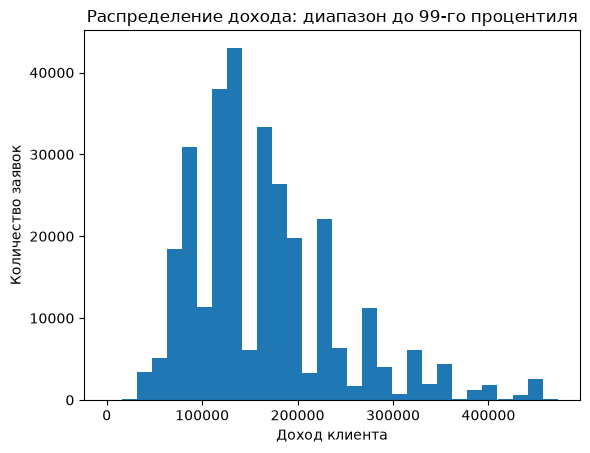

count      307511.00
mean       168797.92
std        237123.15
min         25650.00
1%          45000.00
5%          67500.00
10%         81000.00
25%        112500.00
50%        147150.00
75%        202500.00
90%        270000.00
95%        337500.00
99%        472500.00
max     117000000.00
Name: AMT_INCOME_TOTAL, dtype: float64
12840    117000000.00
203693    18000090.00
246858    13500000.00
77768      9000000.00
131127     6750000.00
103006     4500000.00
187833     4500000.00
204564     4500000.00
287463     4500000.00
181698     3950059.50
Name: AMT_INCOME_TOTAL, dtype: float64


In [113]:
income_total = app_train_raw['AMT_INCOME_TOTAL']
plt.hist(income_total, bins=30, range=(0, income_total.quantile(0.99)))
plt.xlabel('Доход клиента')
plt.ylabel('Количество заявок')
plt.title('Распределение дохода: диапазон до 99-го процентиля')
plt.show()

print(income_total.describe(percentiles=[0.01, 0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]))
print(app_train_raw['AMT_INCOME_TOTAL'].nlargest(10))

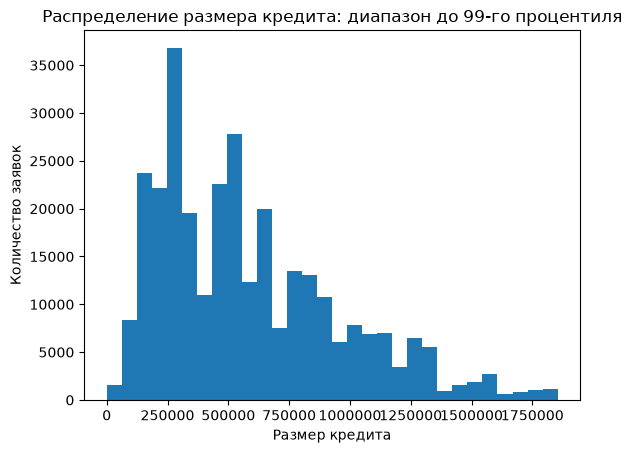

count    307511.00
mean     599026.00
std      402490.78
min       45000.00
1%        76410.00
5%       135000.00
10%      180000.00
25%      270000.00
50%      513531.00
75%      808650.00
90%     1133748.00
95%     1350000.00
99%     1854000.00
max     4050000.00
Name: AMT_CREDIT, dtype: float64
14852    4050000.00
17948    4050000.00
110459   4050000.00
119681   4050000.00
120757   4050000.00
133766   4050000.00
287732   4050000.00
288455   4050000.00
95571    4031032.50
186230   4027680.00
Name: AMT_CREDIT, dtype: float64


In [114]:
credit = app_train_raw['AMT_CREDIT']
plt.hist(credit, bins=30, range=(0, credit.quantile(0.99)))
plt.xlabel('Размер кредита')
plt.ylabel('Количество заявок')
plt.title('Распределение размера кредита: диапазон до 99-го процентиля')
plt.show()
print(credit.describe(percentiles=[0.01, 0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]))
print(app_train_raw['AMT_CREDIT'].nlargest(10))

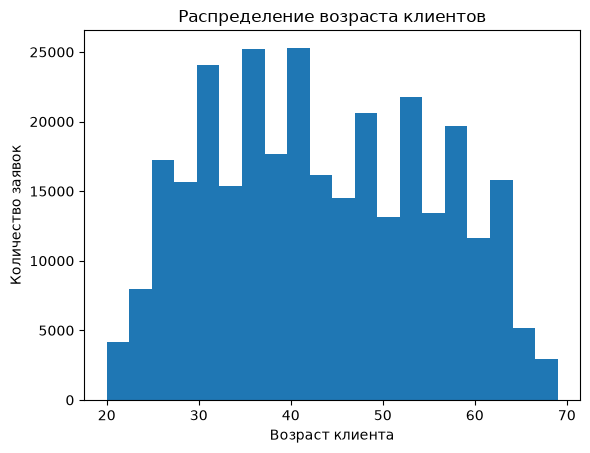

count   307511.00
mean        43.44
std         11.95
min         20.00
25%         34.00
50%         43.00
75%         53.00
max         69.00
Name: DAYS_BIRTH, dtype: float64

In [115]:
days_birth = app_train_raw['DAYS_BIRTH']
age_years = np.floor((days_birth/365).abs())

plt.hist(age_years, bins=20)
plt.xlabel('Возраст клиента')
plt.ylabel('Количество заявок')
plt.title('Распределение возраста клиентов')
plt.show()
age_years.describe()


NAME_INCOME_TYPE
Pensioner     55352
Unemployed       22
Name: count, dtype: int64
Пенсионеров: 55362
Безработных: 22


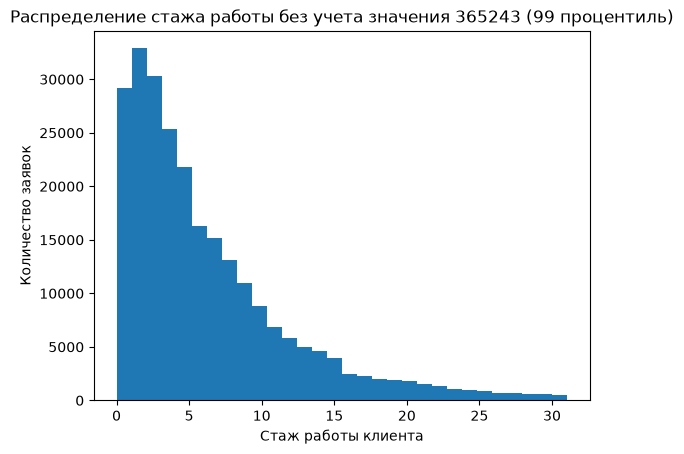

count   252137.00
mean         6.53
std          6.41
min          0.00
25%          2.10
50%          4.52
75%          8.70
max         49.07
Name: DAYS_EMPLOYED, dtype: float64

In [116]:
days_employed = app_train_raw['DAYS_EMPLOYED']
print(app_train_raw[app_train_raw['DAYS_EMPLOYED'] == 365243]['NAME_INCOME_TYPE'].value_counts())
print('Пенсионеров:', len(app_train_raw[app_train_raw['NAME_INCOME_TYPE'] == 'Pensioner']))
print('Безработных:', len(app_train_raw[app_train_raw['NAME_INCOME_TYPE'] == 'Unemployed']))

# Для колонки дней работы есть значение 365243 - повторяется; После просмотра данных выявленно, что это значение соответствует клиентам без работы/пенсионерам
days_employed_filtered = app_train_raw.loc[app_train_raw['DAYS_EMPLOYED'] != 365243, 'DAYS_EMPLOYED']
days_employed_filtered = (days_employed_filtered/365).abs()
plt.hist(days_employed_filtered, bins=30, range=(0, days_employed_filtered.quantile(0.99)))
plt.xlabel('Стаж работы клиента')
plt.ylabel('Количество заявок')
plt.title('Распределение стажа работы без учета значения 365243 (99 процентиль)')
plt.show()

days_employed_filtered.describe()

Максимальный доход 117 000 000 - значение встречается 1 раз<br>
Минимальный доход 25650<br>
Медианный доход 147150<br>

Максимальный кредит 4 050 000 - значение встречается 8 раз<br>
Минимальный кредит 45000<br>
Медиана 513531<br>

Максимальный возраст 69<br>
Минимальный возраст 20<br>
Медианный возраст 43<br>
Средний возраст 43<br>

Стаж клиента на текущем месте работы на момент подачи заявки<br>
Максимальный стаж 49<br>
Минимальный стаж 0<br>
Медианный стаж 4.52<br>
Средний стаж 6.53<br>

не все пенсионеры без текущего стажа работы (спец знач 365243) (55352 из 55362), все безработные без текущего стажа <br>

Доход и сумма кредита имеют правую асимметрию, макс доход сильно выше даже 2-го по значению, необходимо проверить данное значение